# Analyse Exploratoire

### Import des modules

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

### Analyse Exploratoire

In [ ]:
# Chargement du fichier de données
building_consumption = pd.read_csv("2016_Building_Energy_Benchmarking.csv")

# Nombre de lignes et de colonnes
print("Nombre de lignes :", building_consumption.shape[0])
print("Nombre de colonnes :", building_consumption.shape[1])

Nombre de lignes : 3376
Nombre de colonnes : 46


In [ ]:
# Regardons comment un batiment est défini dans ce jeu de données 
building_consumption.head()

,OSEBuildingID,DataYear,BuildingType,PrimaryPropertyType,PropertyName,Address,City,State,ZipCode,TaxParcelIdentificationNumber,...,Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),DefaultData,Comments,ComplianceStatus,Outlier,TotalGHGEmissions,GHGEmissionsIntensity
0,1,2016,NonResidential,Hotel,Mayflower park hotel,405 Olive way,Seattle,WA,98101.0,0659000030,...,1.156514e+06,3946027.0,12764.52930,1276453.0,False,NaN,Compliant,NaN,249.98,2.83
1,2,2016,NonResidential,Hotel,Paramount Hotel,724 Pine street,Seattle,WA,98101.0,0659000220,...,9.504252e+05,3242851.0,51450.81641,5145082.0,False,NaN,Compliant,NaN,295.86,2.86
2,3,2016,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,Seattle,WA,98101.0,0659000475,...,1.451544e+07,49526664.0,14938.00000,1493800.0,False,NaN,Compliant,NaN,2089.28,2.19
3,5,2016,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,Seattle,WA,98101.0,0659000640,...,8.115253e+05,2768924.0,18112.13086,1811213.0,False,NaN,Compliant,NaN,286.43,4.67
4,8,2016,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,Seattle,WA,98121.0,0659000970,...,1.573449e+06,5368607.0,88039.98438,8803998.0,False,NaN,Compliant,NaN,505.01,2.88


In [ ]:
# Regardons le nombre de valeurs manquantes par colonne ainsi que leur type 
building_consumption.info()

<class 'pandas.DataFrame'>
RangeIndex: 3376 entries, 0 to 3375
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    3376 non-null   int64  
 1   DataYear                         3376 non-null   int64  
 2   BuildingType                     3376 non-null   str    
 3   PrimaryPropertyType              3376 non-null   str    
 4   PropertyName                     3376 non-null   str    
 5   Address                          3376 non-null   str    
 6   City                             3376 non-null   str    
 7   State                            3376 non-null   str    
 8   ZipCode                          3360 non-null   float64
 9   TaxParcelIdentificationNumber    3376 non-null   str    
 10  CouncilDistrictCode              3376 non-null   int64  
 11  Neighborhood                     3376 non-null   str    
 12  Latitude                       

#### TERMINER L'ANALYSE EXPLORATOIRE 

réaliseDans la suite : 
- Une analyse descriptive des données, y compris une explication du sens des colonnes gardées, des arguments derrière la suppression de lignes ou de colonnes, des statistiques descriptives et des visualisations pertinentes.

**Objectif** :Nous allons prédire la consommation d'énergie des bâtiments **non destinés à l'habitation** à partir de leurs caractéristiques (surface, usage, année de construction, quartier…).

Étapes de cette partie :
1. Vérifier les doublons
2. Regarder les valeurs manquantes
3. Garder uniquement les bâtiments non résidentiels
4. Supprimer les relevés non fiables
5. Choisir la variable cible
6. Faire quelques graphiques
7. Traiter les valeurs manquantes restantes

#### 1. Doublons

In [ ]:
# Chaque bâtiment a un identifiant unique : OSEBuildingID
nb_doublons = building_consumption["OSEBuildingID"].duplicated().sum()
print("Nombre de doublons :", nb_doublons)

Nombre de doublons : 0


Il n'y a pas de doublon : chaque ligne correspond à un bâtiment différent.

#### 2. Valeurs manquantes

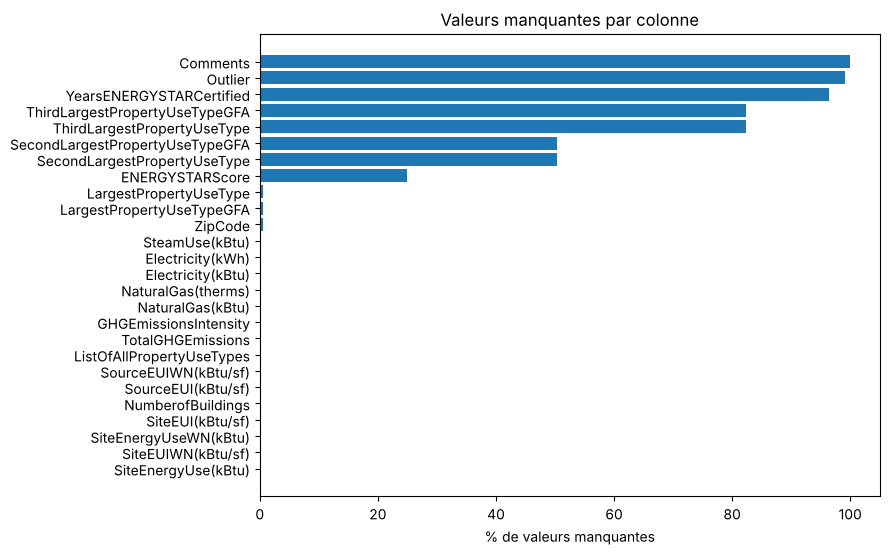

In [ ]:
# Pourcentage de valeurs manquantes par colonne (seulement les colonnes concernées)
pourcentage_manquant = building_consumption.isna().mean() * 100
pourcentage_manquant = pourcentage_manquant[pourcentage_manquant > 0].sort_values()

plt.figure(figsize=(8, 6))
plt.barh(pourcentage_manquant.index, pourcentage_manquant.values)
plt.xlabel("% de valeurs manquantes")
plt.title("Valeurs manquantes par colonne")
plt.show()

- `Comments` est complètement vide : on la supprimera.
- `Outlier` est presque vide : une case vide veut dire « bâtiment normal ».
- `SecondLargestPropertyUseType` et `ThirdLargestPropertyUseType` sont vides quand le bâtiment n'a qu'un seul usage.
- `ENERGYSTARScore` : ce score est calculé à partir de la consommation, on ne doit donc **pas** l'utiliser pour prédire la consommation.

#### 3. Garder uniquement les bâtiments non résidentiels

In [ ]:
# Les différents types de bâtiments
building_consumption["BuildingType"].value_counts()

BuildingType
NonResidential          1460
Multifamily LR (1-4)    1018
Multifamily MR (5-9)     580
Multifamily HR (10+)     110
SPS-District K-12         98
Nonresidential COS        85
Campus                    24
Nonresidential WA          1
Name: count, dtype: int64

In [ ]:
# On enlève les logements : les types "Multifamily ..." 
df = building_consumption[~building_consumption["BuildingType"].str.contains("Multifamily")]

# On enlève aussi les usages principaux qui sont du logement
df = df[~df["PrimaryPropertyType"].isin(["Low-Rise Multifamily", "Residence Hall"])]

print("Nombre de bâtiments non résidentiels :", len(df))

Nombre de bâtiments non résidentiels : 1644


#### 4. Supprimer les relevés non fiables

In [ ]:
# La ville a marqué certains bâtiments comme "Outlier" (valeurs anormales) : on les enlève
df = df[df["Outlier"].isna()]

# On garde seulement les relevés validés ("Compliant")
df = df[df["ComplianceStatus"] == "Compliant"]

# On enlève les bâtiments avec une consommation manquante ou nulle
df = df[df["SiteEnergyUse(kBtu)"] > 0]

# On enlève les bâtiments avec un nombre d'étages anormal (une église de 99 étages par exemple)
df = df[df["NumberofFloors"] < 90]

print("Nombre de bâtiments après nettoyage :", len(df))

Nombre de bâtiments après nettoyage : 1524


In [ ]:
# Quelques bâtiments ont 0 bâtiment ou 0 étage : c'est une erreur de saisie, on remplace par 1
df.loc[df["NumberofBuildings"] == 0, "NumberofBuildings"] = 1
df.loc[df["NumberofFloors"] == 0, "NumberofFloors"] = 1

# Statistiques descriptives des principales colonnes numériques
df[["YearBuilt", "NumberofBuildings", "NumberofFloors", "PropertyGFATotal", "SiteEnergyUse(kBtu)"]].describe()

,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,SiteEnergyUse(kBtu)
count,1524.000000,1524.000000,1524.000000,1.524000e+03,1.524000e+03
mean,1961.619423,1.215879,4.231627,1.221225e+05,8.943073e+06
std,32.833943,3.055191,6.370959,3.085527e+05,3.154151e+07
min,1900.000000,1.000000,1.000000,1.128500e+04,5.713320e+04
25%,1930.000000,1.000000,1.000000,2.892225e+04,1.245740e+06
50%,1965.000000,1.000000,2.000000,4.831500e+04,2.735489e+06
75%,1989.000000,1.000000,4.000000,1.071275e+05,7.431820e+06
max,2015.000000,111.000000,76.000000,9.320156e+06,8.739237e+08


#### 5. Choix de la variable cible

On choisit **`SiteEnergyUse(kBtu)`** : c'est la consommation totale d'énergie du bâtiment, ce que demande la ville.

Les autres colonnes de consommation (électricité, gaz, émissions, EUI…) ne seront **pas** utilisées pour prédire, car on ne les connaît pas pour un nouveau bâtiment (sinon ce serait de la triche : on appelle ça une **fuite de données**).

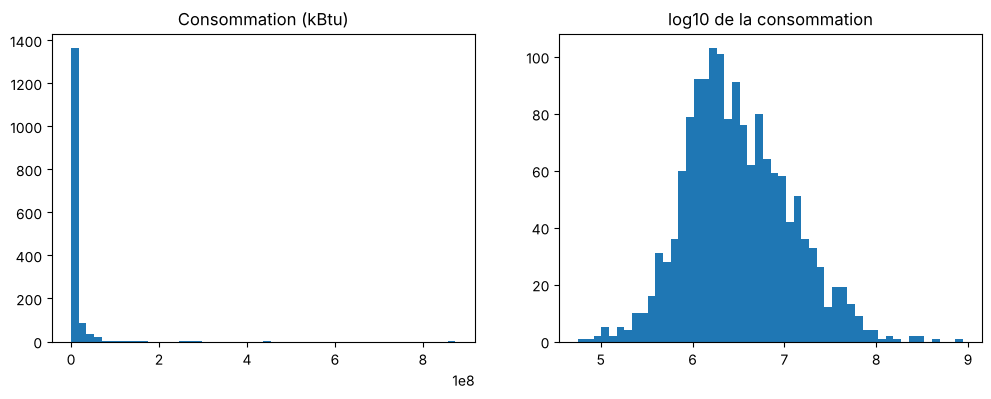

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribution de la consommation brute
axes[0].hist(df["SiteEnergyUse(kBtu)"], bins=50)
axes[0].set_title("Consommation (kBtu)")

# Distribution du logarithme de la consommation
axes[1].hist(np.log10(df["SiteEnergyUse(kBtu)"]), bins=50)
axes[1].set_title("log10 de la consommation")
plt.show()

La consommation brute est très déséquilibrée : beaucoup de petits bâtiments et quelques très gros (hôpitaux, universités). Avec le **logarithme**, la distribution devient plus régulière (en forme de cloche). On prédira donc le **log10 de la consommation**.

In [ ]:
# Création de la cible en log
df["log_conso"] = np.log10(df["SiteEnergyUse(kBtu)"])

#### 6. Quelques graphiques

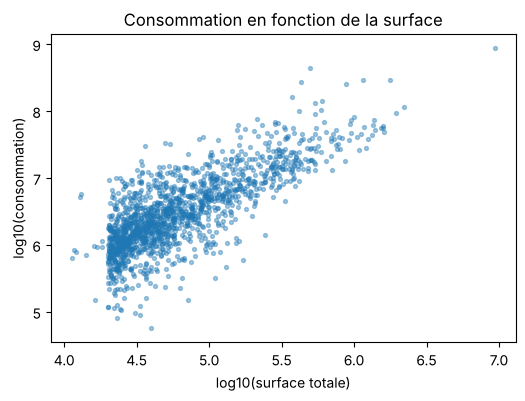

In [ ]:
# Consommation en fonction de la surface (les deux en log)
plt.figure(figsize=(6, 4))
plt.scatter(np.log10(df["PropertyGFATotal"]), df["log_conso"], s=8, alpha=0.4)
plt.xlabel("log10(surface totale)")
plt.ylabel("log10(consommation)")
plt.title("Consommation en fonction de la surface")
plt.show()

Plus le bâtiment est grand, plus il consomme : la relation est presque une droite en échelle log. **La surface sera la variable la plus importante.**

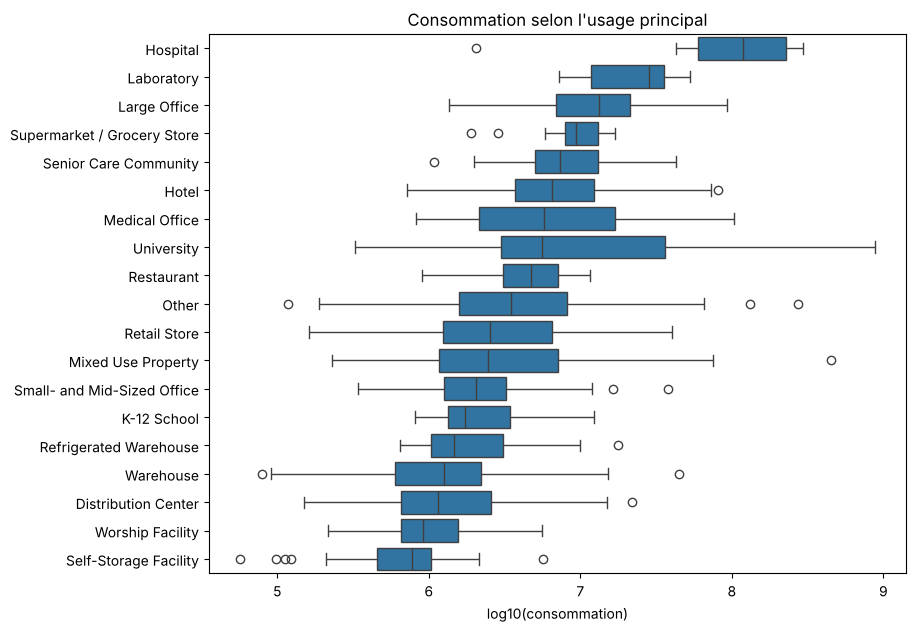

In [ ]:
# Consommation selon l'usage principal du bâtiment
plt.figure(figsize=(9, 7))
ordre = df.groupby("PrimaryPropertyType")["log_conso"].median().sort_values(ascending=False).index
sns.boxplot(data=df, y="PrimaryPropertyType", x="log_conso", order=ordre)
plt.xlabel("log10(consommation)")
plt.ylabel("")
plt.title("Consommation selon l'usage principal")
plt.show()

L'usage compte beaucoup : les hôpitaux, universités et laboratoires consomment bien plus que les entrepôts ou les lieux de culte.

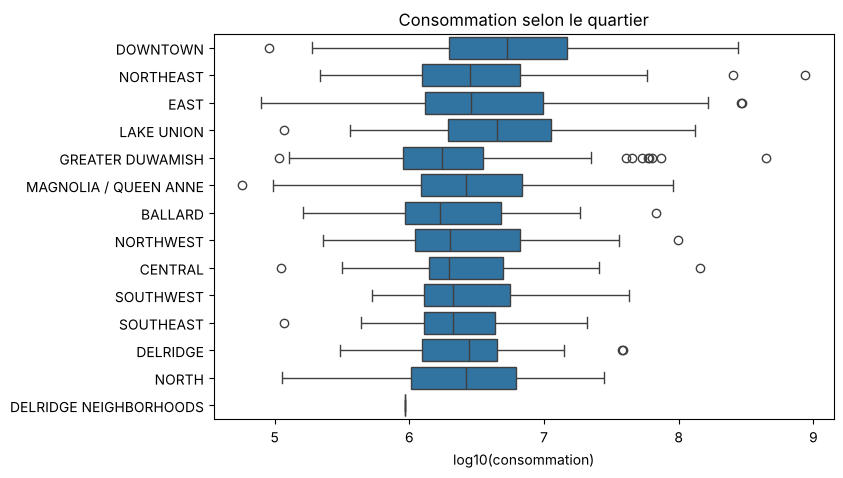

In [ ]:
# Consommation selon le quartier (on met les noms en majuscules car "North" et "NORTH" existent)
df["Neighborhood"] = df["Neighborhood"].str.upper()

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, y="Neighborhood", x="log_conso")
plt.xlabel("log10(consommation)")
plt.ylabel("")
plt.title("Consommation selon le quartier")
plt.show()

Le centre-ville (DOWNTOWN) consomme plus car il y a beaucoup de grands immeubles de bureaux. Les autres quartiers sont assez proches.

#### 7. Valeurs manquantes restantes

In [ ]:
# Pas de 2e ou 3e usage -> on met "None" et une surface de 0
df["SecondLargestPropertyUseType"] = df["SecondLargestPropertyUseType"].fillna("None")
df["SecondLargestPropertyUseTypeGFA"] = df["SecondLargestPropertyUseTypeGFA"].fillna(0)
df["ThirdLargestPropertyUseType"] = df["ThirdLargestPropertyUseType"].fillna("None")
df["ThirdLargestPropertyUseTypeGFA"] = df["ThirdLargestPropertyUseTypeGFA"].fillna(0)

# On supprime les colonnes inutiles ou interdites (fuite de données)
df = df.drop(columns=["Comments", "Outlier", "ComplianceStatus", "DefaultData", "ENERGYSTARScore",
                      "YearsENERGYSTARCertified", "DataYear", "City", "State"])

print("Dimensions finales :", df.shape)

Dimensions finales : (1524, 38)


**Bilan de l'analyse exploratoire**
- On passe de 3 376 bâtiments à 1 524 bâtiments non résidentiels et fiables (puis 1 503 après le retrait des relevés aberrants, dans la préparation des features).
- La cible est le log10 de `SiteEnergyUse(kBtu)`.
- La **surface** et l'**usage** du bâtiment semblent être les deux facteurs les plus importants.

# Modélisation 

### Import des modules 

In [ ]:
#Selection
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV, 
    cross_validate,
)
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error 
from sklearn.inspection import permutation_importance

#Preprocess
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline

#Modèles
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

### Feature Engineering

Dans la suite : Enrichir le jeu de données actuel avec de nouvelles features issues de celles existantes. 

On crée de nouvelles variables à partir des colonnes qui décrivent le bâtiment. On n'utilise **jamais** les colonnes de consommation (électricité, gaz…) pour éviter la fuite de données.

In [ ]:
# 1) Âge du bâtiment en 2016 (année des relevés)
df["Age"] = 2016 - df["YearBuilt"]

# 2) Surface en log (la relation avec la consommation est linéaire en log)
df["log_surface"] = np.log10(df["PropertyGFATotal"])

# 3) Surface moyenne par étage
df["surface_par_etage"] = df["PropertyGFABuilding(s)"] / df["NumberofFloors"]

# 4) Part de la surface occupée par le parking
df["part_parking"] = df["PropertyGFAParking"] / df["PropertyGFATotal"]

# 5) Nombre d'usages du bâtiment (1, 2 ou 3)
df["nb_usages"] = 1 + (df["SecondLargestPropertyUseType"] != "None") + (df["ThirdLargestPropertyUseType"] != "None")

# 6) Part de la surface du 1er usage (1 = bâtiment à un seul usage)
surface_usages = (df["LargestPropertyUseTypeGFA"].fillna(df["PropertyGFABuilding(s)"])
                  + df["SecondLargestPropertyUseTypeGFA"] + df["ThirdLargestPropertyUseTypeGFA"])
df["part_usage_principal"] = df["LargestPropertyUseTypeGFA"].fillna(df["PropertyGFABuilding(s)"]) / surface_usages

df[["Age", "log_surface", "surface_par_etage", "part_parking", "nb_usages", "part_usage_principal"]].describe()

,Age,log_surface,surface_par_etage,part_parking,nb_usages,part_usage_principal
count,1524.000000,1524.000000,1.524000e+03,1524.000000,1524.000000,1524.000000
mean,54.380577,4.799174,3.977753e+04,0.065692,1.774278,0.849917
std,32.833943,0.423527,2.458394e+05,0.144548,0.792426,0.188678
min,1.000000,4.052502,1.818000e+03,0.000000,1.000000,0.333333
25%,27.000000,4.461232,1.216970e+04,0.000000,1.000000,0.707220
50%,51.000000,4.684082,2.065233e+04,0.000000,2.000000,1.000000
75%,86.000000,5.029897,3.275750e+04,0.000000,2.000000,1.000000
max,116.000000,6.969423,9.320156e+06,0.895023,3.000000,1.000000


In [ ]:
# 7) Le bâtiment est-il raccordé au gaz ou au réseau de vapeur ? (1 = oui, 0 = non)
# On garde seulement "oui/non", jamais la quantité consommée.
df["a_du_gaz"] = (df["NaturalGas(kBtu)"] > 0).astype(int)
df["a_de_la_vapeur"] = (df["SteamUse(kBtu)"] > 0).astype(int)

print("Part des bâtiments avec du gaz :", round(df["a_du_gaz"].mean() * 100), "%")
print("Part des bâtiments avec de la vapeur :", round(df["a_de_la_vapeur"].mean() * 100), "%")

Part des bâtiments avec du gaz : 71 %
Part des bâtiments avec de la vapeur : 7 %


| Nouvelle variable | Idée |
|---|---|
| `Age` | Les bâtiments anciens et récents n'ont pas la même isolation |
| `log_surface` | La surface est le facteur principal, en log pour une relation linéaire |
| `surface_par_etage` | Forme du bâtiment (entrepôt large ou tour fine) |
| `part_parking` | Un parking consomme peu |
| `nb_usages`, `part_usage_principal` | Bâtiment à un ou plusieurs usages |
| `a_du_gaz`, `a_de_la_vapeur` | Équipement du bâtiment |

### Préparation des features pour la modélisation

Dans la suite :
* Nous supprimerons toutes les colonnes peu pertinentes pour la modélisation.
* Tracerons la distribution de la cible pour vous familiariser avec l'ordre de grandeur. En cas d'outliers,nous  mettrons en place une démarche pour les supprimer.
* Nous nous débarrasserons-vous des features redondantes en utilisant une matrice de corrélation.
* Réalisatuion des différents graphiques pour comprendre le lien entre vos features et la target (boxplots, scatterplots, pairplot si votre nombre de features numériques n'est pas très élevé).
*  Séparons notre jeu de données en un Pandas DataFrame X (ensemble de feautures) et Pandas Series y (votre target).


#### 1. Distribution de la cible et outliers

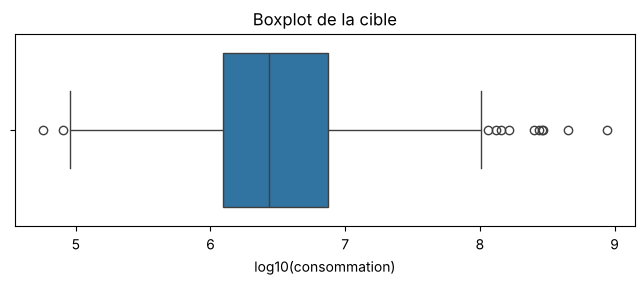

Consommation minimale : 57133.19922 kBtu
Consommation médiane : 2735488.75 kBtu
Consommation maximale : 873923712.0 kBtu


In [ ]:
# Boxplot de la cible (en log) pour repérer les valeurs extrêmes
plt.figure(figsize=(8, 2.5))
sns.boxplot(x=df["log_conso"])
plt.xlabel("log10(consommation)")
plt.title("Boxplot de la cible")
plt.show()

print("Consommation minimale :", df["SiteEnergyUse(kBtu)"].min(), "kBtu")
print("Consommation médiane :", df["SiteEnergyUse(kBtu)"].median(), "kBtu")
print("Consommation maximale :", df["SiteEnergyUse(kBtu)"].max(), "kBtu")

In [ ]:
# Quels sont les bâtiments en dehors des moustaches du boxplot ? (méthode de l'écart interquartile)
q1 = df["log_conso"].quantile(0.25)
q3 = df["log_conso"].quantile(0.75)
ecart = q3 - q1
extremes = df[(df["log_conso"] < q1 - 1.5 * ecart) | (df["log_conso"] > q3 + 1.5 * ecart)]
extremes[["PropertyName", "PrimaryPropertyType", "PropertyGFATotal", "SiteEnergyUse(kBtu)"]]

,PropertyName,PrimaryPropertyType,PropertyGFATotal,SiteEnergyUse(kBtu)
35,Plant 2 Site,Mixed Use Property,494835,4.483853e+08
124,Seattle Children's Hospital Main Campus,Hospital,879000,2.538325e+08
167,Swedish Cherry Hill,Hospital,597519,1.434230e+08
170,Harborview Medical Center,Hospital,1158691,2.930908e+08
340,Weintraub/Hutchinson/Thomas,Other,535947,1.313739e+08
558,WestinBuilding,Other,429405,2.746822e+08
618,Swedish First Hill,Hospital,1765970,2.916144e+08
1494,Entire Campus,University,2200000,1.146485e+08
1577,"A1 Self Storage, LLC",Self-Storage Facility,39952,5.713320e+04
3009,Auto Accessories Inc.,Warehouse,23040,7.971180e+04


Les valeurs extrêmes sont de **vrais bâtiments** (grands hôpitaux, université de Washington, petits entrepôts). Leur consommation s'explique par leur taille et leur usage. Ce ne sont pas des erreurs, donc **on les garde** : le modèle doit aussi apprendre à prédire ces bâtiments.

En revanche, certains bâtiments ont une consommation **incohérente avec leur usage**. Par exemple, un hôpital qui consomme 10 fois moins par m² que les autres hôpitaux : c'est sûrement un compteur incomplet ou une erreur de saisie. Pour les repérer, on compare la **consommation par m²** (`SiteEUI`) de chaque bâtiment à celle des bâtiments **du même type**. On utilise cette colonne seulement pour nettoyer, jamais pour prédire.

In [ ]:
# Consommation par m² en log (pour comparer des bâtiments de tailles très différentes)
log_eui = np.log10(df["SiteEUI(kBtu/sf)"])

# Pour chaque type de bâtiment : la médiane, et l'écart "habituel" à cette médiane (MAD)
mediane_type = log_eui.groupby(df["PrimaryPropertyType"]).transform("median")
ecart_type_robuste = log_eui.groupby(df["PrimaryPropertyType"]).transform(lambda s: (s - s.median()).abs().median())

# Score : à combien d'écarts "habituels" le bâtiment se trouve de la médiane de son type
score = 0.6745 * (log_eui - mediane_type) / ecart_type_robuste

# Au-delà de 3,5, on considère que le relevé est aberrant (seuil classique)
aberrants = df[score.abs() > 3.5]
print("Nombre de bâtiments aberrants :", len(aberrants))
aberrants[["PropertyName", "PrimaryPropertyType", "SiteEUI(kBtu/sf)"]]

Nombre de bâtiments aberrants : 21


,PropertyName,PrimaryPropertyType,SiteEUI(kBtu/sf)
162,South Park,Large Office,159.899994
253,3101 Western Avenue,Large Office,161.199997
309,Fisher Plaza - West Building,Mixed Use Property,707.299988
320,1441 N. 34th Street,Large Office,179.100006
328,1000 Denny Building,Large Office,176.000000
512,"Ocean Beauty Seafoods, LLC",Large Office,210.100006
516,501 Elliott Ave West,Large Office,231.399994
595,Westcore River Street,Distribution Center,2.100000
601,200 SW Michigan,Small- and Mid-Sized Office,465.500000
641,4545 Building 751,Large Office,273.299988


In [ ]:
# On retire ces bâtiments
df = df[score.abs() <= 3.5]
print("Nombre de bâtiments restants :", len(df))

Nombre de bâtiments restants : 1503


On retire 21 bâtiments, soit environ 1 % du jeu de données (1 524 → 1 503). Exemples : *Park West Skilled Nursing*, classé hôpital, consomme 19 kBtu/m² contre environ 220 pour les autres hôpitaux ; plusieurs « bureaux » consomment 3 à 5 fois plus que les bureaux comparables (sûrement un usage non déclaré : data center, cuisine…).

**Limite de la méthode** : la règle est automatique. Elle retire aussi le *Bullitt Center*, un immeuble de bureaux très connu pour consommer très peu d'énergie : sa faible consommation est réelle. Sur 21 bâtiments, ce cas reste isolé, mais il montre qu'un filtre automatique doit toujours être vérifié à la main.

#### 2. Features redondantes (matrice de corrélation)

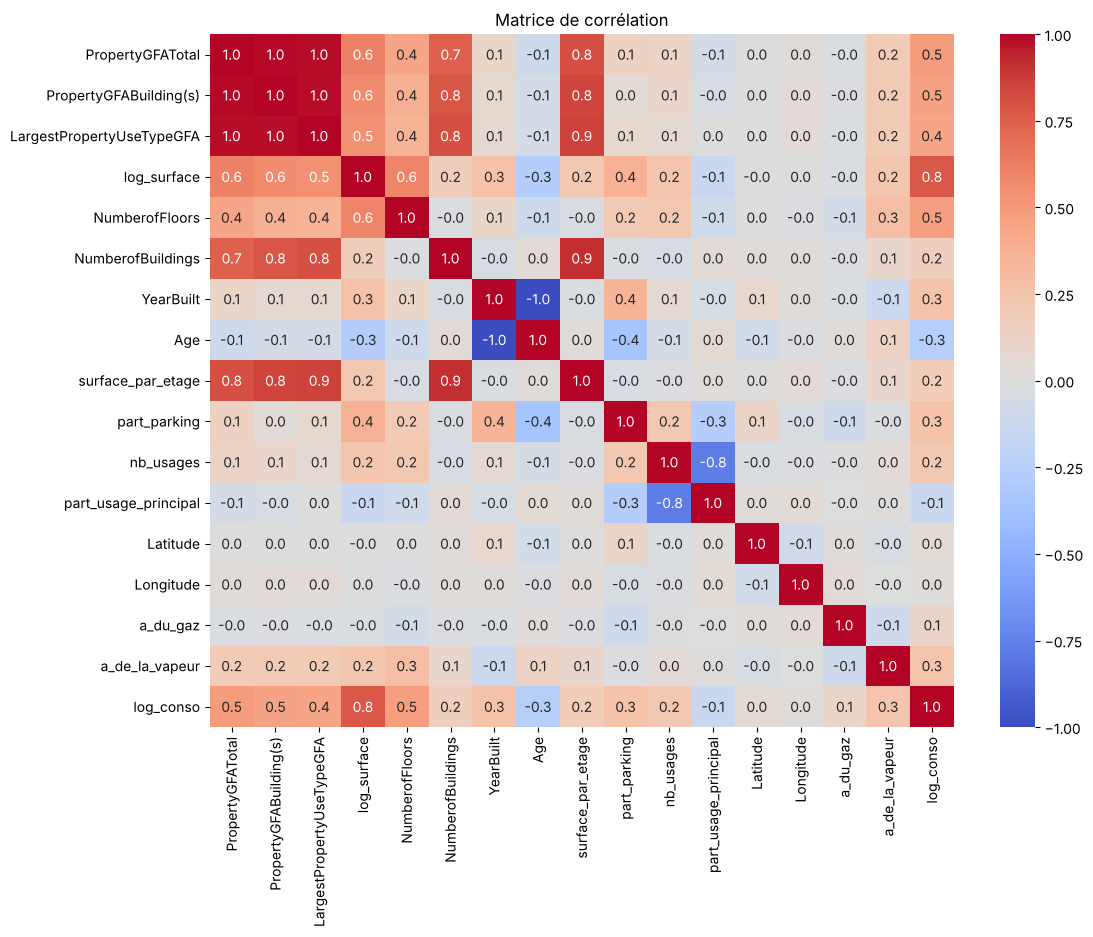

In [ ]:
colonnes_numeriques = ["PropertyGFATotal", "PropertyGFABuilding(s)", "LargestPropertyUseTypeGFA", "log_surface",
                       "NumberofFloors", "NumberofBuildings", "YearBuilt", "Age", "surface_par_etage",
                       "part_parking", "nb_usages", "part_usage_principal", "Latitude", "Longitude",
                       "a_du_gaz", "a_de_la_vapeur", "log_conso"]

correlation = df[colonnes_numeriques].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(correlation, annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de corrélation")
plt.show()

Variables très corrélées entre elles (corrélation proche de 1 ou -1) : elles donnent la même information, on n'en garde qu'une.
- `PropertyGFATotal`, `PropertyGFABuilding(s)`, `LargestPropertyUseTypeGFA` et `log_surface` → on garde **`log_surface`**.
- `YearBuilt` et `Age` → on garde **`Age`**.
- `nb_usages` et `part_usage_principal` → on garde **`part_usage_principal`**.
- `NumberofBuildings` et `surface_par_etage` (corrélation 0,9, à cause de quelques grands campus) → on garde **`surface_par_etage`**.

#### 3. Liens entre les features et la cible

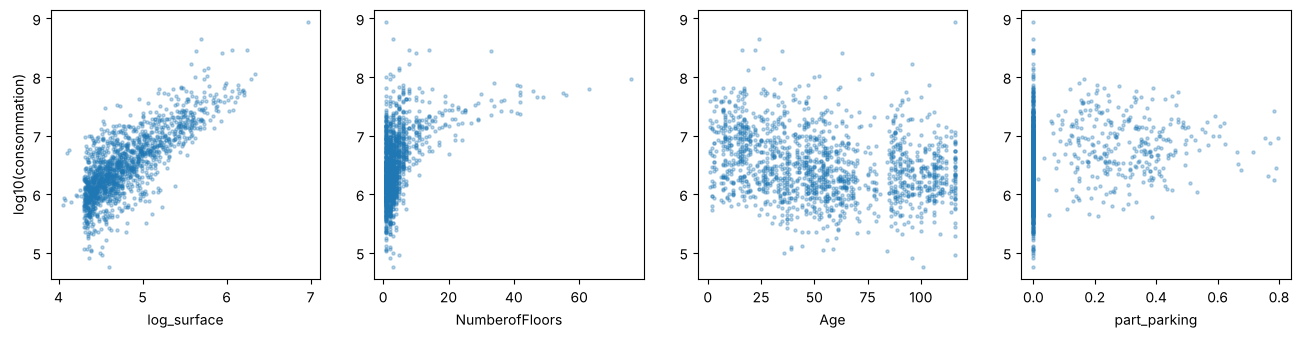

In [25]:
# Nuages de points de quelques variables numériques avec la cible
variables = ["log_surface", "NumberofFloors", "Age", "part_parking"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for i in range(4):
    axes[i].scatter(df[variables[i]], df["log_conso"], s=5, alpha=0.3)
    axes[i].set_xlabel(variables[i])
axes[0].set_ylabel("log10(consommation)")
plt.show()

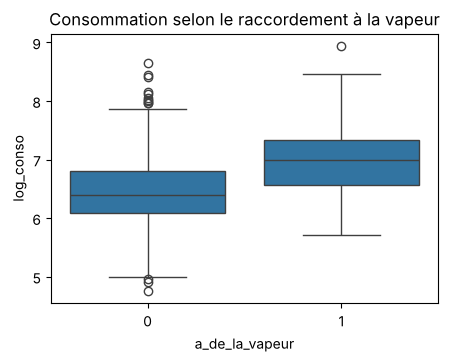

In [26]:
# Boxplot : la consommation est-elle plus forte pour les bâtiments raccordés à la vapeur ?
plt.figure(figsize=(5, 3.5))
sns.boxplot(data=df, x="a_de_la_vapeur", y="log_conso")
plt.title("Consommation selon le raccordement à la vapeur")
plt.show()

La surface a un lien très fort avec la consommation. Le nombre d'étages et le raccordement à la vapeur aussi (ce sont souvent de grands immeubles du centre). L'âge a un lien faible.

#### 4. Séparation X / y

In [27]:
# Variables utilisées pour prédire
features_numeriques = ["log_surface", "NumberofFloors", "Age", "surface_par_etage",
                       "part_parking", "part_usage_principal", "Latitude", "Longitude",
                       "a_du_gaz", "a_de_la_vapeur"]
features_categorielles = ["PrimaryPropertyType", "Neighborhood"]

X = df[features_numeriques + features_categorielles]
y = df["log_conso"]

print("X :", X.shape)
print("y :", y.shape)

X : (1503, 12)
y : (1503,)


#### 5. Encodage des variables catégorielles

In [28]:
# Les modèles ne comprennent que des nombres.
# get_dummies crée une colonne 0/1 pour chaque catégorie (encodage "one-hot").
X = pd.get_dummies(X, columns=features_categorielles, dtype=int)

print("Nombre de colonnes après encodage :", X.shape[1])
X.head()

Nombre de colonnes après encodage : 43


,log_surface,NumberofFloors,Age,surface_par_etage,part_parking,part_usage_principal,Latitude,Longitude,a_du_gaz,a_de_la_vapeur,...,Neighborhood_DOWNTOWN,Neighborhood_EAST,Neighborhood_GREATER DUWAMISH,Neighborhood_LAKE UNION,Neighborhood_MAGNOLIA / QUEEN ANNE,Neighborhood_NORTH,Neighborhood_NORTHEAST,Neighborhood_NORTHWEST,Neighborhood_SOUTHEAST,Neighborhood_SOUTHWEST
0,4.946619,12,89,7369.500000,0.000000,1.000000,47.61220,-122.33799,1,1,...,1,0,0,0,0,0,0,0,0,0
1,5.015217,11,20,8045.636364,0.145453,0.809918,47.61317,-122.33393,1,0,...,1,0,0,0,0,0,0,0,0,0
2,5.980508,41,47,18521.756098,0.205748,1.000000,47.61393,-122.33810,1,1,...,1,0,0,0,0,0,0,0,0,0
3,4.787602,10,90,6132.000000,0.000000,1.000000,47.61412,-122.33664,1,1,...,1,0,0,0,0,0,0,0,0,0
4,5.244475,18,36,6310.000000,0.353115,0.644776,47.61375,-122.34047,1,0,...,1,0,0,0,0,0,0,0,0,0


### Comparaison de différents modèles supervisés

Pour la suite :
* Pour chaque algorithme que nous allons tester, nous devons:
    * Réalisons au préalable une séparation en jeu d'apprentissage et jeu de test via une validation croisée.
    * Si les features quantitatives que nous souhaitons utiliser ont des ordres de grandeur très différents les uns des autres, et que vous utilisez un algorithme de regression qui est sensible à cette différence, alors il faut réaliser un scaling (normalisation) de la donnée au préalable.
    * Entrainer le modèle sur le jeu de Train
    * Prédire la cible sur la donnée de test (nous appelons cette étape, l'inférence).
    * Calculer les métriques de performance R2, MAE et RMSE sur le jeu de train et de test.
    * Interpréter les résultats pour juger de la fiabilité de l'algorithme.
* nouss pouvons choisir par exemple de tester un modèle linéaire, un modèle à base d'arbres et un modèle de type SVM
* Déterminerons le modèle le plus performant parmi ceux testés.

#### 1. Séparation train / test

In [ ]:
# 80 % des bâtiments pour l'entraînement, 20 % pour le test
# random_state=42 permet d'avoir toujours le même découpage (résultats reproductibles)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train :", X_train.shape[0], "bâtiments")
print("Test :", X_test.shape[0], "bâtiments")

Train : 1202 bâtiments
Test : 301 bâtiments


#### 2. Premier modèle : la régression linéaire

In [ ]:
# La régression linéaire est sensible aux ordres de grandeur des variables -> on fait un scaling.
# make_pipeline enchaîne le scaling puis le modèle (le scaling est appris seulement sur le train).
modele_lineaire = make_pipeline(StandardScaler(), LinearRegression())

# Validation croisée à 5 plis sur le jeu d'entraînement
scores = cross_validate(modele_lineaire, X_train, y_train, cv=5, scoring="r2", return_train_score=True)
print("R2 moyen train (CV) :", round(scores["train_score"].mean(), 3))
print("R2 moyen validation (CV) :", round(scores["test_score"].mean(), 3))

# Entraînement sur tout le train
modele_lineaire.fit(X_train, y_train)

# Prédiction sur le test (inférence)
y_pred = modele_lineaire.predict(X_test)

# Métriques sur le test
print("R2 test :", round(r2_score(y_test, y_pred), 3))
print("MAE test :", round(mean_absolute_error(y_test, y_pred), 3))
print("RMSE test :", round(np.sqrt(mean_squared_error(y_test, y_pred)), 3))

R2 moyen train (CV) : 0.774
R2 moyen validation (CV) : 0.754
R2 test : 0.752
MAE test : 0.22
RMSE test : 0.291


- Le **R²** mesure la part de la consommation expliquée par le modèle (1 = parfait, 0 = pas mieux que la moyenne).
- La **MAE** est l'erreur moyenne, ici en log10 : une MAE de 0,2 signifie que la prédiction se trompe en moyenne d'un facteur 10^0,2 ≈ 1,6.
- La **RMSE** ressemble à la MAE mais pénalise plus les grosses erreurs.

Les scores de train et de validation sont proches : le modèle ne fait pas d'**overfit** (il n'apprend pas par cœur)--> il n'est pas un mauvais apprenant.

#### 3. Une fonction pour tester tous les modèles de la même façon

In [ ]:
def evaluer_modele(nom, modele):
    # 1) Validation croisée (5 plis) sur le train
    cv = cross_validate(modele, X_train, y_train, cv=5, scoring="r2", return_train_score=True)

    # 2) Entraînement sur tout le train
    modele.fit(X_train, y_train)

    # 3) Prédictions sur le train et sur le test
    pred_train = modele.predict(X_train)
    pred_test = modele.predict(X_test)

    # 4) Métriques
    resultat = {
        "Modèle": nom,
        "R2 validation (CV)": cv["test_score"].mean(),
        "R2 train": r2_score(y_train, pred_train),
        "R2 test": r2_score(y_test, pred_test),
        "MAE train": mean_absolute_error(y_train, pred_train),
        "MAE test": mean_absolute_error(y_test, pred_test),
        "RMSE train": np.sqrt(mean_squared_error(y_train, pred_train)),
        "RMSE test": np.sqrt(mean_squared_error(y_test, pred_test)),
    }
    return resultat

In [32]:
# Les modèles à tester (avec leurs paramètres par défaut)
# Scaling pour la régression linéaire et le SVR, pas besoin pour les modèles à arbres
modeles = {
    "Dummy (moyenne)": DummyRegressor(),
    "Régression linéaire": make_pipeline(StandardScaler(), LinearRegression()),
    "SVR": make_pipeline(StandardScaler(), SVR()),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

resultats = []
for nom in modeles:
    resultats.append(evaluer_modele(nom, modeles[nom]))

resultats = pd.DataFrame(resultats).set_index("Modèle")
resultats.round(3)

,R2 validation (CV),R2 train,R2 test,MAE train,MAE test,RMSE train,RMSE test
Modèle,,,,,,,
Dummy (moyenne),-0.005,0.000,-0.002,0.448,0.460,0.559,0.585
Régression linéaire,0.754,0.773,0.752,0.203,0.220,0.267,0.291
SVR,0.711,0.852,0.678,0.158,0.238,0.215,0.332
Random Forest,0.731,0.964,0.705,0.080,0.229,0.106,0.318
Gradient Boosting,0.754,0.837,0.727,0.172,0.222,0.226,0.305


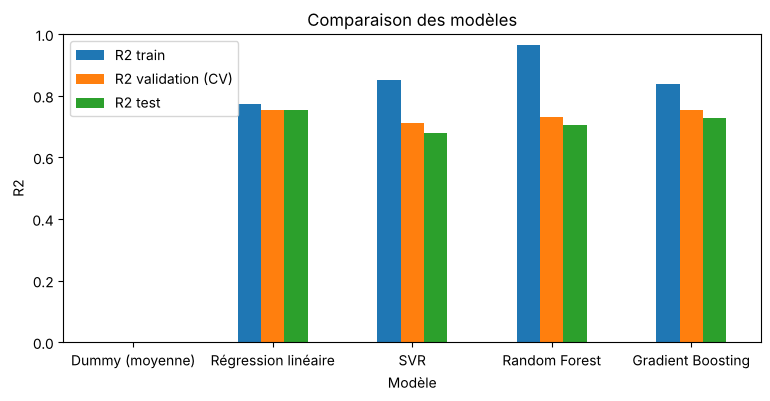

In [33]:
# Graphique : R2 sur le train et sur le test pour chaque modèle
resultats[["R2 train", "R2 validation (CV)", "R2 test"]].plot(kind="bar", figsize=(9, 4))
plt.ylabel("R2")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.title("Comparaison des modèles")
plt.show()

**Interprétation**
- Le **Dummy** (qui prédit toujours la moyenne) a un R² de 0 : c'est la référence. Tous les autres modèles font beaucoup mieux.
- La **régression linéaire** (R² validation 0,754, test 0,752) et le **Gradient Boosting** (R² validation 0,754, test 0,727) sont les meilleurs : ils sont à égalité en validation croisée.
- La **Random Forest** a un R² de 0,96 sur le train mais seulement 0,71 sur le test : elle fait de l'**overfit** (elle apprend par cœur les bâtiments du train). Le **SVR** aussi (0,85 contre 0,68).
- La régression linéaire n'a pas d'overfit (train et test proches), mais elle n'a pas de paramètres à régler pour s'améliorer.

➡️ **On choisit le Gradient Boosting** pour l'étape suivante : il est à égalité avec la régression linéaire en validation croisée, et on peut encore l'améliorer en réglant ses hyperparamètres. La régression linéaire reste la référence à battre.

### Optimisation et interprétation du modèle

A réaliser :
* Reprennez le meilleur algorithme que vous avez sécurisé via l'étape précédente, et réalisez une GridSearch de petite taille sur au moins 3 hyperparamètres.
* Si le meilleur modèle fait partie de la famille des modèles à arbres (RandomForest, GradientBoosting) alors utilisez la fonctionnalité feature importance pour identifier les features les plus impactantes sur la performance du modèle. Sinon, utilisez la méthode Permutation Importance de sklearn. 

#### 1. Test rapide sur une petite grille (10 combinaisons)

In [34]:
# On vérifie d'abord que le code marche sur une petite grille : 2 x 5 = 10 combinaisons
petite_grille = {
    "max_depth": [2, 3],
    "learning_rate": [0.01, 0.05, 0.1, 0.2, 0.3],
}

test_grid = GridSearchCV(GradientBoostingRegressor(random_state=42), petite_grille, cv=5, scoring="r2")
test_grid.fit(X_train, y_train)

print("Le code fonctionne. Meilleurs paramètres :", test_grid.best_params_)

Le code fonctionne. Meilleurs paramètres : {'learning_rate': 0.1, 'max_depth': 3}


#### 2. GridSearch complète

In [35]:
# 3 x 3 x 3 x 2 x 3 = 162 combinaisons (entre 100 et 500, comme recommandé)
# Attention : le calcul prend quelques minutes.
grille = {
    "n_estimators": [100, 300, 500],      # nombre d'arbres
    "learning_rate": [0.02, 0.05, 0.1],   # vitesse d'apprentissage
    "max_depth": [2, 3, 4],               # profondeur de chaque arbre
    "min_samples_leaf": [1, 5],           # nombre minimum de bâtiments par feuille
    "subsample": [0.7, 0.85, 1.0],        # part des bâtiments utilisés pour chaque arbre
}

grid = GridSearchCV(GradientBoostingRegressor(random_state=42), grille, cv=5, scoring="r2", n_jobs=-1)
grid.fit(X_train, y_train)

print("Meilleurs paramètres :", grid.best_params_)
print("Meilleur R2 en validation croisée :", round(grid.best_score_, 3))

Meilleurs paramètres : {'learning_rate': 0.02, 'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 500, 'subsample': 0.7}
Meilleur R2 en validation croisée : 0.759


#### 3. Évaluation du modèle optimisé

In [ ]:
# On évalue le modèle optimisé avec la même fonction que les autres modèles
modele_optimise = GradientBoostingRegressor(random_state=42, **grid.best_params_)
resultat_optimise = evaluer_modele("Gradient Boosting optimisé", modele_optimise)

resultats.loc["Gradient Boosting optimisé"] = pd.Series(resultat_optimise)
resultats.loc[["Régression linéaire", "Gradient Boosting", "Gradient Boosting optimisé"]].round(3)

,R2 validation (CV),R2 train,R2 test,MAE train,MAE test,RMSE train,RMSE test
Modèle,,,,,,,
Régression linéaire,0.754,0.773,0.752,0.203,0.220,0.267,0.291
Gradient Boosting,0.754,0.837,0.727,0.172,0.222,0.226,0.305
Gradient Boosting optimisé,0.759,0.847,0.735,0.169,0.218,0.219,0.301


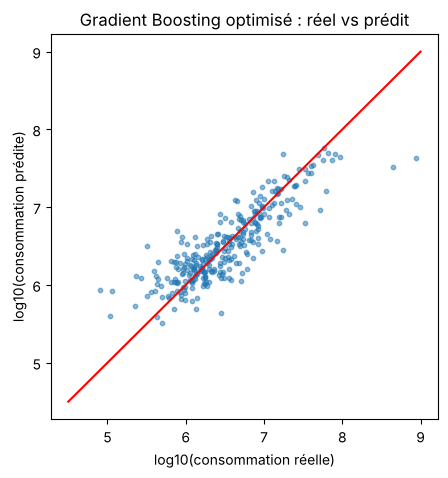

In [ ]:
# Valeurs réelles contre valeurs prédites sur le test
y_pred = modele_optimise.predict(X_test)

plt.figure(figsize=(5, 5))
plt.scatter(y_test, y_pred, s=10, alpha=0.5)
plt.plot([4.5, 9], [4.5, 9], color="red")   # droite parfaite : prédit = réel
plt.xlabel("log10(consommation réelle)")
plt.ylabel("log10(consommation prédite)")
plt.title("Gradient Boosting optimisé : réel vs prédit")
plt.show()

**Interprétation**
- La GridSearch a trouvé : 500 arbres, `learning_rate` = 0,02, `max_depth` = 3, `min_samples_leaf` = 1, `subsample` = 0,7. Beaucoup d'arbres qui apprennent lentement, chacun sur 70 % des bâtiments tirés au hasard : cela rend le modèle plus robuste.
- Le R² en validation croisée passe de **0,754** (paramètres par défaut) à **0,759**. Le gain est faible : le modèle était déjà correct avec les paramètres par défaut.
- Sur le test, le Gradient Boosting optimisé (R² 0,735, MAE 0,218, RMSE 0,301) fait mieux que le Gradient Boosting par défaut (R² 0,727). Il a la **meilleure MAE** de tous les modèles, mais un R² un peu plus bas que la régression linéaire (0,752). Les écarts sont petits : les deux modèles se valent sur ce jeu de test, et on garde le choix fait avec la validation croisée.
- Le R² train (0,85) est plus haut que le R² test (0,74) : il reste un peu d'overfit, mais beaucoup moins que la Random Forest.
- Une MAE de 0,22 en log10 veut dire que le modèle se trompe en moyenne d'un **facteur 1,7** environ (10^0,22). C'est suffisant pour estimer un ordre de grandeur de consommation, pas pour remplacer un vrai relevé.

#### 4. Feature importance

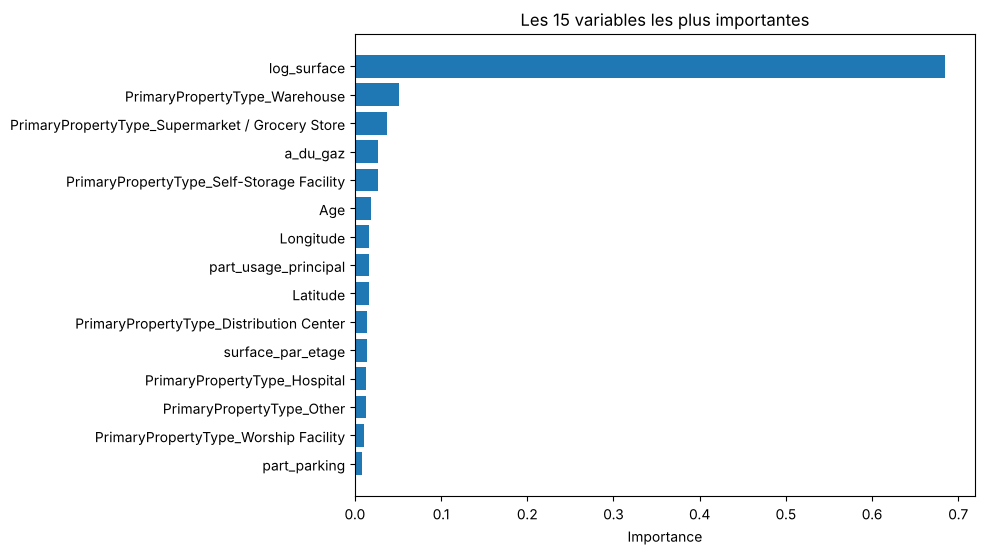

In [38]:
# Importance de chaque variable dans le modèle optimisé
importance = pd.Series(modele_optimise.feature_importances_, index=X_train.columns)
importance = importance.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
plt.barh(importance.index[::-1], importance.values[::-1])
plt.xlabel("Importance")
plt.title("Les 15 variables les plus importantes")
plt.show()

**Interprétation**
- **La surface (`log_surface`) est de loin la variable la plus importante** (environ 69 % de l'importance) : plus un bâtiment est grand, plus il consomme.
- Viennent ensuite les **usages** : entrepôt, self-storage (qui consomment peu au m²) et supermarché (qui consomme beaucoup).
- Le **raccordement au gaz** et l'**âge** du bâtiment ont un petit rôle (2 à 3 % chacun).
- La localisation (`Latitude`, `Longitude`) et la forme du bâtiment comptent très peu.

**Conclusion** : la consommation d'un bâtiment dépend surtout de **sa taille** et de **son usage**. Le modèle final (Gradient Boosting optimisé) explique environ 74 % de la variation de la consommation sur des bâtiments qu'il n'a jamais vus, avec une erreur moyenne d'un facteur 1,7.